# Assignment 02 – Notebook 2: Pretrained Diffusion Model (CO4)
Uses **Stable Diffusion v1.5** (pretrained, no training). Runtime → **T4 GPU**, then Run all. Screenshot the image grids.

In [1]:
!pip -q install diffusers transformers accelerate safetensors

In [2]:
import torch, matplotlib.pyplot as plt
from diffusers import StableDiffusionPipeline, DPMSolverMultistepScheduler
pipe = StableDiffusionPipeline.from_pretrained("stable-diffusion-v1-5/stable-diffusion-v1-5", torch_dtype=torch.float16).to("cuda")
pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
pipe.safety_checker = None
def gen(prompts, seed=7, steps=25, size=512):
    gens = [torch.Generator("cuda").manual_seed(seed + i) for i in range(len(prompts))]
    return pipe(prompts, num_inference_steps=steps, guidance_scale=7.5, height=size, width=size, generator=gens).images
def show(imgs, titles, fname):
    fig, ax = plt.subplots(1, len(imgs), figsize=(5*len(imgs), 5.6))
    for a, im, t in zip(ax, imgs, titles):
        a.imshow(im); a.set_title(t, fontsize=9, wrap=True); a.axis("off")
    plt.tight_layout(); plt.savefig(fname, dpi=130); plt.show()

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

## 1. Same subject as the DCGAN dataset (flowers)
Same domain as Notebook 1 so the two models can be compared directly.

  0%|          | 0/25 [00:00<?, ?it/s]

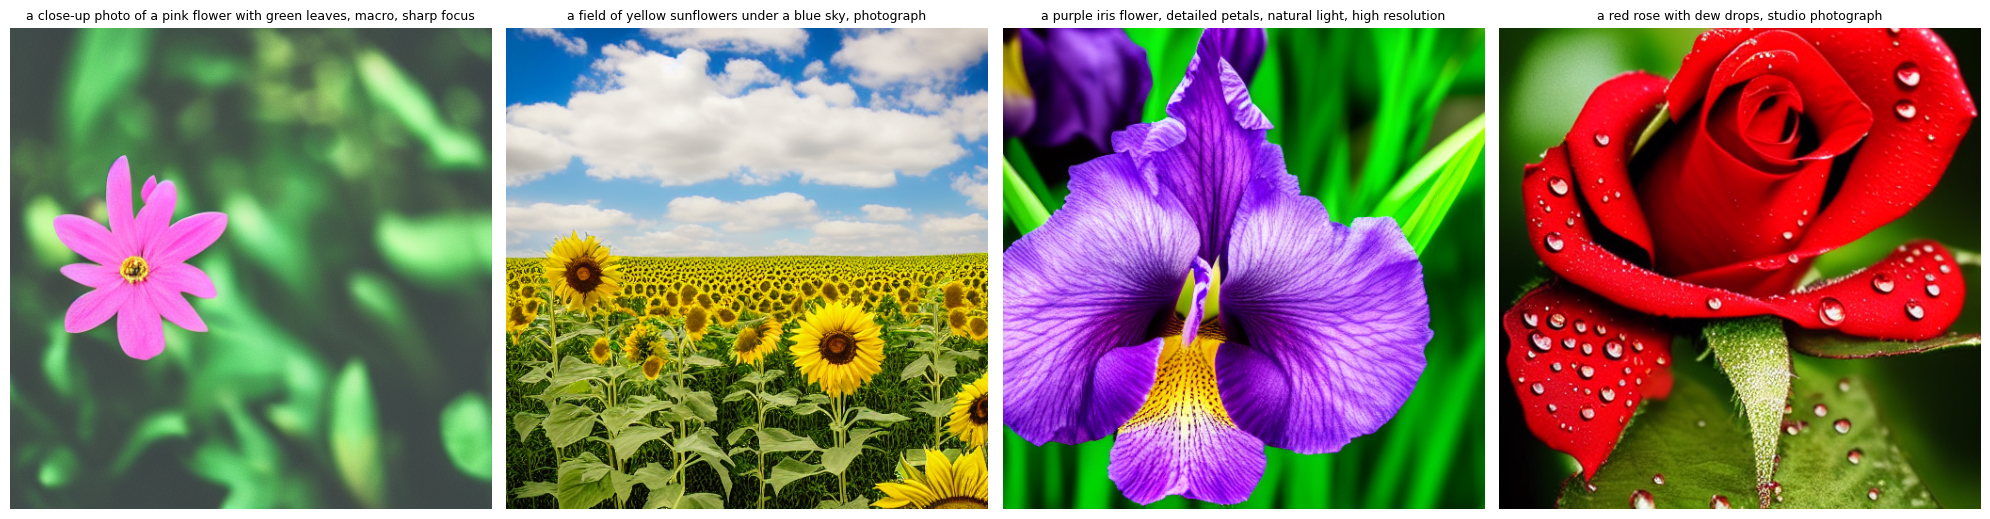

In [3]:
P1 = ["a close-up photo of a pink flower with green leaves, macro, sharp focus",
      "a field of yellow sunflowers under a blue sky, photograph",
      "a purple iris flower, detailed petals, natural light, high resolution",
      "a red rose with dew drops, studio photograph"]
show(gen(P1), P1, "sd_flowers.png")

## 2. Open-ended prompts (shows range and limitations)

  0%|          | 0/25 [00:00<?, ?it/s]

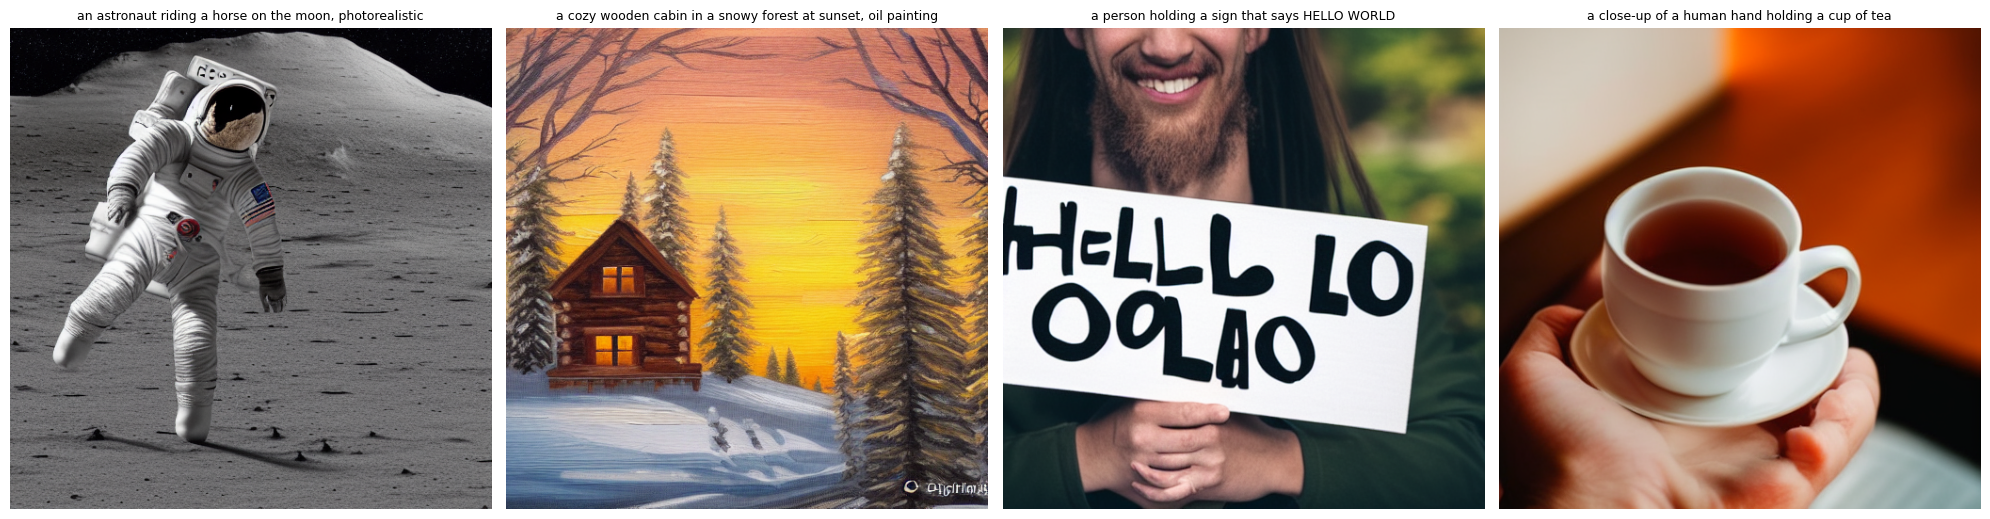

In [4]:
P2 = ["an astronaut riding a horse on the moon, photorealistic",
      "a cozy wooden cabin in a snowy forest at sunset, oil painting",
      "a person holding a sign that says HELLO WORLD",
      "a close-up of a human hand holding a cup of tea"]
show(gen(P2), P2, "sd_general.png")

## 3. Effect of denoising steps (quality vs. speed)

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

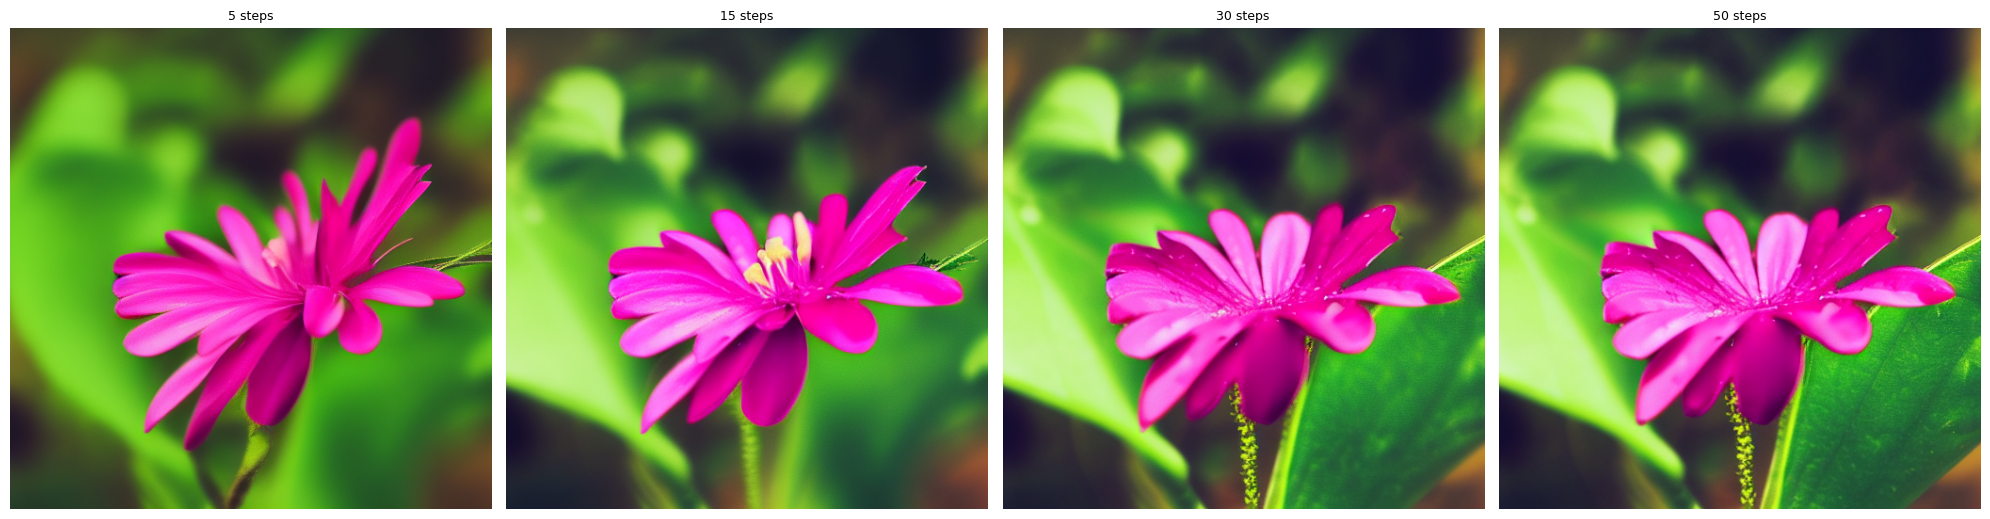

In [5]:
p = "a close-up photo of a pink flower with green leaves, macro, sharp focus"
steps = [5, 15, 30, 50]
imgs = [gen([p], seed=3, steps=s)[0] for s in steps]
show(imgs, [f"{s} steps" for s in steps], "sd_steps.png")